In [18]:
import open_clip
import torch
from PIL import Image
from matplotlib import pyplot as plt

from homework_3.functions import parse_img, get_cache, api_response_to_tensor

In [19]:
class ClipModel(torch.nn.Module):
    def __init__(self, weights_path, model_name="ViT-B-32", pretrained="laion2b_s34b_b79k"):
        super().__init__()
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.clip_backbone, _, self.preprocess = open_clip.create_model_and_transforms(model_name=model_name,
                                                                                       pretrained=pretrained)
        for p in self.clip_backbone.parameters():
            p.requires_grad = False
        self.clip_backbone.eval()
        self.tokenizer = open_clip.get_tokenizer('ViT-B-32')

        self.class_labels = ["class1", "class2", "class3", "class4"]
        self.class_tokens = self.tokenizer(self.class_labels)
        self.class_features = self.clip_backbone.encode_text(self.class_tokens)
        self.class_features /= self.class_features.norm(dim=-1, keepdim=True)
        self.class_features = self.class_features.to(self.device)

        self.head = torch.nn.Linear(self.clip_backbone.visual.output_dim,
                                    self.clip_backbone.visual.output_dim)
        self.clip_backbone.to(self.device)
        self.head.to(self.device)
        self._load_head(weights_path)

    def _load_head(self, weights_path):
        try:
            self.head.load_state_dict(
                torch.load(weights_path, map_location=self.device))
        except FileNotFoundError:
            exit("Could not find the provided filepath for loading head weights.\n"
                 f"Make sure {weights_path} exists.")

    def forward(self, images: torch.Tensor, head=True) -> torch.Tensor:
        with torch.no_grad():
            image_features = self.clip_backbone.encode_image(images)
            if head:
                image_features = self.head(image_features)
            image_features = image_features / image_features.norm(dim=-1, keepdim=True)
            class_similarity = (100.0 * image_features @ self.class_features.T).softmax(dim=-1)
        return class_similarity

Image surprised.png
Hash: 068d76a31dfc66be7a9c7d1867cc8c6c
API results:	tensor([0.3911, 0.6089, 0.9324, 0.0676])
Baseline results	tensor([[0.3035, 0.3757, 0.2373, 0.0835]], device='cuda:0')
HEAD results:	tensor([[2.6854e-03, 2.2008e-01, 7.7686e-01, 3.7101e-04]], device='cuda:0')


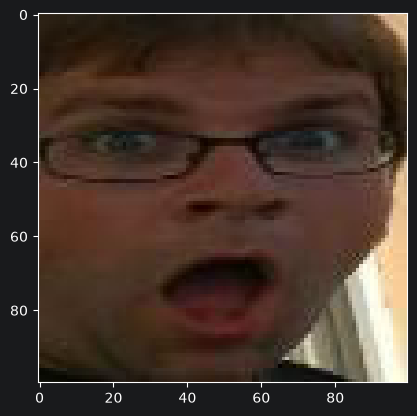

In [21]:
WEIGHTS_PATH = "../weights/100_2.pth"
IMG_DIR = "../img"

clip_model = ClipModel(WEIGHTS_PATH)

image_file = "surprised.png"

try:
    raw_img = Image.open(f"{IMG_DIR}/{image_file}")
except FileNotFoundError:
    exit("File not found")

_, img_hash = parse_img(raw_img)
api_response = get_cache(img_hash)
# We are only testing results from cache here
# noinspection bad-argument-type
label = api_response_to_tensor(api_response)
preprocessed_image = clip_model.preprocess(raw_img).unsqueeze(0).cuda()

output_baseline = clip_model(preprocessed_image, head=False)
output = clip_model(preprocessed_image)

plt.imshow(raw_img)


print(f"Image {image_file}\n"
      f"Hash: {img_hash}\n"
      f"API results:\t{label}\n"
      f"Baseline results\t{output_baseline}\n"
      f"HEAD results:\t{output}")